# Demo - Creating Vector Embeddings with Gemini Emdedding Model
https://www.youtube.com/watch?v=AgmC_IaqQ2A

## Import the required packages

In [ ]:
!pip install google-genai pandas scikit-learn ipython
from google import genai
from google.genai import types
import pandas as pd
from sklearn.metrics.pairwise import cosine_similarity
from IPython.display import display

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 36.7 MB/s eta 0:00:00


## Set the API Key

In [ ]:
from google.colab import userdata

api_key = userdata.get('GOOGLE_API_KEY')

if not api_key:
    raise RuntimeError(
        "GOOGLE_API_KEY not found. "
        "Add it via Colab → 🔑 Secrets → enable Notebook access."
    )

client = genai.Client(api_key=api_key)
print(repr(api_key))


## Generate the Embeddings

In [ ]:
texts = [
    "How do I write a Python function?",
    "How can I create a class in Java?",
    "Which smartphone has the best camera?",
    "What is the best Android phone?",
    "Turn off the lights.",
    "Switch the lights off.",
    "Apple released a new iPhone.",
    "Apple is my favorite fruit."
]

# By Default Dimension = 3072 but you can control dimentions using output_dimensionality=768, 1536

result = client.models.embed_content(
    model="gemini-embedding-001",
    contents=texts,
    config=types.EmbedContentConfig(task_type="SEMANTIC_SIMILARITY",
                                    outputDimensionality=768)
)

for text, embedding_obj in zip(texts, result.embeddings):
    embedding = embedding_obj.values
    print("Text:", text)
    print("Embedding length:", len(embedding))
    print("Embeddings:", embedding)
    print("-" * 50)




Text: How do I write a Python function?
Embedding length: 768
Embeddings: [-0.007334515, -0.006950146, 0.018683976, -0.04260659, -0.013810179, -0.02353132, 0.0017563101, 0.012470875, 0.03482735, 0.007981162, -0.021974491, -0.008932356, -0.03219012, 0.008530096, 0.13476881, -0.009113698, -0.023886729, 0.01596416, 0.005160837, -0.011251521, 0.0020869148, 0.015941188, -0.004785726, -0.020768173, -0.009616656, -0.015237897, 0.0153389685, 0.022661485, 0.036309812, -0.022520773, 0.0061276644, 0.02676682, 0.009503948, 0.015846258, -0.003522161, 0.013055647, 0.01262321, 0.005883274, 0.014447721, 0.04268203, -0.02048863, -0.008275668, 0.0029366165, -0.0018869105, 0.021970829, 0.005502179, -0.006817169, -0.022217361, -0.0030909744, 0.009136699, -0.00038050817, -0.0068712486, -0.011236744, -0.17840478, 0.008931584, -0.0010842282, -0.0068541258, 0.01222939, 0.0003866231, 0.0074349977, -0.023397373, 0.03202773, -0.033427857, -0.032966875, 0.004789494, -0.010730537, 0.03292936, -0.022680353, -0.0020

## Create a 3x3 table to show the similarity matrix

In [ ]:

df = pd.DataFrame(
    cosine_similarity([e.values for e in result.embeddings]),
    index=texts,
    columns=texts,
)
display(df)

,How do I write a Python function?,How can I create a class in Java?,Which smartphone has the best camera?,What is the best Android phone?,Turn off the lights.,Switch the lights off.,Apple released a new iPhone.,Apple is my favorite fruit.
How do I write a Python function?,1.000000,0.792966,0.683139,0.692409,0.668049,0.664706,0.704239,0.692279
How can I create a class in Java?,0.792966,1.000000,0.697506,0.711553,0.667857,0.663003,0.694784,0.687971
Which smartphone has the best camera?,0.683139,0.697506,1.000000,0.917305,0.650889,0.655075,0.784778,0.697292
What is the best Android phone?,0.692409,0.711553,0.917305,1.000000,0.641943,0.644259,0.767397,0.700769
Turn off the lights.,0.668049,0.667857,0.650889,0.641943,1.000000,0.988772,0.663434,0.632479
Switch the lights off.,0.664706,0.663003,0.655075,0.644259,0.988772,1.000000,0.672718,0.631576
Apple released a new iPhone.,0.704239,0.694784,0.784778,0.767397,0.663434,0.672718,1.000000,0.790114
Apple is my favorite fruit.,0.692279,0.687971,0.697292,0.700769,0.632479,0.631576,0.790114,1.000000


## Visualise in 3D Using PCA

### What is PCA (Principal Component Analysis)?

PCA is a technique used to reduce the number of dimensions in data while keeping as much important information as possible.

In simple terms:

> PCA compresses high-dimensional data into fewer dimensions so we can visualize or analyze it more easily.


Humans cannot visualize 768-dimensional space

So we use PCA to transform:

768 dimensions → 3 dimensions

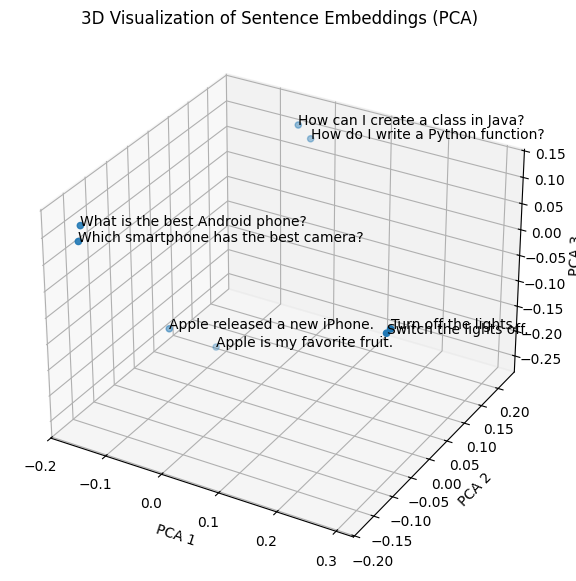

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA


# Convert embeddings to numpy matrix
embeddings = np.array([e.values for e in result.embeddings])

# Reduce dimensions: 768 → 3
pca = PCA(n_components=3)
reduced = pca.fit_transform(embeddings)

df = pd.DataFrame(reduced, columns=["x", "y", "z"])
df["text"] = texts

fig = plt.figure(figsize=(10,7))
ax = fig.add_subplot(111, projection="3d")

ax.scatter(df["x"], df["y"], df["z"])

for i, txt in enumerate(df["text"]):
    ax.text(df["x"][i], df["y"][i], df["z"][i], txt)

ax.set_title("3D Visualization of Sentence Embeddings (PCA)")
ax.set_xlabel("PCA 1")
ax.set_ylabel("PCA 2")
ax.set_zlabel("PCA 3")

plt.show()

In [ ]:
import plotly.express as px

fig = px.scatter_3d(
    df,
    x="x",
    y="y",
    z="z",
    text="text",
    title="3D Embedding Visualization",
    height=800,
    width=1100
)

fig.show()

# Demo - Storing and Querying ChromaDB

## 1. Install Chroma

In [ ]:
!pip install "opentelemetry-api<=1.42.1,>=1.39" \
            "opentelemetry-sdk<=1.42.1,>=1.39" \
            "opentelemetry-semantic-conventions==0.63b1" \
            "opentelemetry-exporter-otlp-proto-grpc<=1.42.1,>=1.39"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 71.8/71.8 kB 1.5 MB/s eta 0:00:00
  Attempting uninstall: opentelemetry-proto
    Found existing installation: opentelemetry-proto 1.44.0
    Uninstalling opentelemetry-proto-1.44.0:
      Successfully uninstalled opentelemetry-proto-1.44.0
  Attempting uninstall: opentelemetry-exporter-otlp-proto-common
    Found existing installation: opentelemetry-exporter-otlp-proto-common 1.44.0
    Uninstalling opentelemetry-exporter-otlp-proto-common-1.44.0:
      Successfully uninstalled opentelemetry-exporter-otlp-proto-common-1.44.0
  Attempting uninstall: opentelemetry-exporter-otlp-proto-grpc
    Found existing installation: opentelemetry-exporter-otlp-proto-grpc 1.44.0
    Uninstalling opentelemetry-exporter-otlp-proto-grpc-1.44.0:
      Successfully uninstalled opentelemetry-exporter-otlp-proto-grpc-1.44.0


In [ ]:
!pip show opentelemetry-exporter-otlp-proto-grpc
!pip install pipdeptree
!pipdeptree --reverse -p opentelemetry-exporter-otlp-proto-grpc

Name: opentelemetry-exporter-otlp-proto-grpc
Version: 1.42.1
Summary: OpenTelemetry Collector Protobuf over gRPC Exporter
Home-page: https://github.com/open-telemetry/opentelemetry-python/tree/main/exporter/opentelemetry-exporter-otlp-proto-grpc
Author: 
Author-email: OpenTelemetry Authors <cncf-opentelemetry-contributors@lists.cncf.io>
License: 
Location: /usr/local/lib/python3.13/dist-packages
Requires: googleapis-common-protos, grpcio, opentelemetry-api, opentelemetry-exporter-otlp-proto-common, opentelemetry-proto, opentelemetry-sdk, typing-extensions
Required-by: chromadb
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 16.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 133.2/133.2 kB 9.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.9/84.9 kB 6.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 140.8/140.8 kB 7.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 321.7/321.7 kB 12.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━

In [ ]:
!pip check

No broken requirements found.


In [ ]:
!pip install chromadb

## 2. Store Embeddings in ChromaDB

In [ ]:
import chromadb
from chromadb.config import Settings

# Create Chroma client (local persistent DB)
chroma_client = chromadb.Client(
    Settings(
        persist_directory="./chroma_db"
    )
)

# Create collection
collection = chroma_client.get_or_create_collection(
    name="semantic_test"
)

# Extract embeddings
embeddings = []
ids = []

for i, embedding_obj in enumerate(result.embeddings):
    embeddings.append(embedding_obj.values)
    ids.append(f"id_{i}")

# Store in Chroma
collection.add(
    ids=ids,
    documents=texts,
    embeddings=embeddings
)

print("Embeddings stored successfully!")

Embeddings stored successfully!


In [ ]:
query = "programming"

query_embedding = client.models.embed_content(
    model="gemini-embedding-001",
    contents=[query],
    config=types.EmbedContentConfig(
        task_type="SEMANTIC_SIMILARITY",
        outputDimensionality=768
    )
).embeddings[0].values

results = collection.query(
    query_embeddings=[query_embedding],
    n_results=3
)

print(results["documents"])

[['How do I write a Python function?', 'How can I create a class in Java?', 'Apple released a new iPhone.']]
